# Volatility Surface Analysis

Quantitative analysis of SPY implied volatility across strike and maturity.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
project_root = Path.cwd().parent

vol_surface = pd.read_csv(
    project_root / "data" / "spy_vol_surface_2026-09-15.csv",
    parse_dates=["expiration"],
)

In [3]:
vol_surface.head()

,ts_event,rtype,publisher_id,instrument_id,side,price,size,flags,bid_px_00,ask_px_00,...,symbol,instrument_class,strike_price,expiration,moneyness,mid_price,spread_pct,quote_age_min,T,implied_vol
0,2026-09-15 19:25:33.031662052+00:00,193,30,1325400485,N,4.64,82,192,4.63,4.67,...,SPY 270319C00850000,C,850.0,2027-03-19 00:00:00+00:00,1.122883,4.650,0.008602,4.449472,0.506849,0.127464
1,2026-09-15 19:27:28.426357169+00:00,193,30,1325418678,N,5.41,1,192,5.37,5.41,...,SPY 270319C00845000,C,845.0,2027-03-19 00:00:00+00:00,1.116278,5.390,0.007421,2.526227,0.506849,0.128391
2,2026-09-15 19:28:53.706464719+00:00,193,30,1325407793,N,36.01,1,192,35.93,36.10,...,SPY 270319C00765000,C,765.0,2027-03-19 00:00:00+00:00,1.010595,36.015,0.004720,1.104892,0.506849,0.163645
3,2026-09-15 19:29:45.211121641+00:00,193,30,1325404170,N,32.95,1,192,32.89,33.05,...,SPY 270319C00770000,C,770.0,2027-03-19 00:00:00+00:00,1.017200,32.970,0.004853,0.246481,0.506849,0.160317
4,2026-09-15 19:29:23.187338048+00:00,193,30,1325407776,N,10.79,1,192,10.75,10.83,...,SPY 270319C00820000,C,820.0,2027-03-19 00:00:00+00:00,1.083252,10.790,0.007414,0.613544,0.506849,0.134848


In [4]:
atm_surface = vol_surface[(vol_surface["moneyness"] >= 0.95) & (vol_surface["moneyness"] <= 1.05)].copy()

In [5]:
atm_surface[["expiration", "moneyness", "implied_vol"]].head(10)

,expiration,moneyness,implied_vol
2,2027-03-19 00:00:00+00:00,1.010595,0.163645
3,2027-03-19 00:00:00+00:00,1.017200,0.160317
5,2027-03-19 00:00:00+00:00,1.037016,0.151056
9,2027-03-19 00:00:00+00:00,1.003990,0.167076
11,2027-03-19 00:00:00+00:00,1.023805,0.157087
15,2026-09-18 00:00:00+00:00,1.019842,0.132540
16,2026-09-18 00:00:00+00:00,1.011916,0.142358
17,2026-09-18 00:00:00+00:00,1.013237,0.140492
19,2026-11-20 00:00:00+00:00,1.010595,0.143011
20,2026-09-18 00:00:00+00:00,1.010595,0.144559


In [6]:
atm_surface.shape

(153, 24)

In [7]:
atm_surface.groupby("expiration").size()

expiration
2026-09-18 00:00:00+00:00    51
2026-10-16 00:00:00+00:00    67
2026-11-20 00:00:00+00:00    14
2026-12-18 00:00:00+00:00    12
2027-03-19 00:00:00+00:00     9
dtype: int64

In [8]:
oct_atm = atm_surface[atm_surface["expiration"] == pd.Timestamp("2026-10-16", tz="UTC")].copy()

In [9]:
oct_atm.shape

(67, 24)

In [10]:
beta, alpha = np.polyfit(
    oct_atm["moneyness"],
    oct_atm["implied_vol"],
    1
)

print("Alpha:", alpha)
print("ATM skew:", beta)

Alpha: 1.114654638715657
ATM skew: -0.9709771285182857


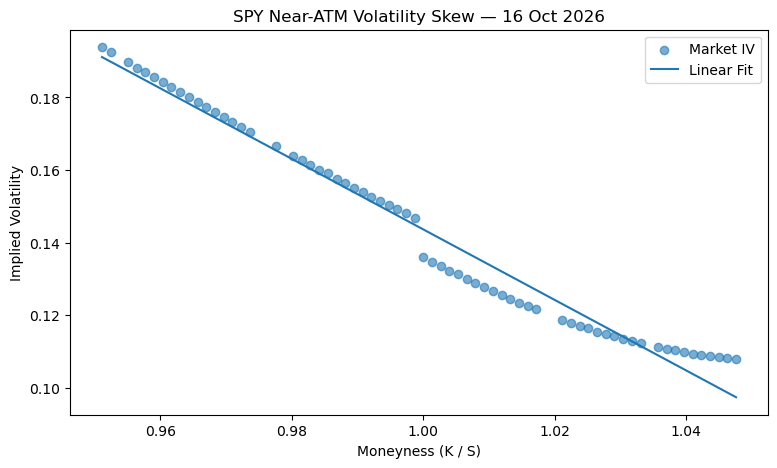

In [11]:
plt.figure(figsize=(9, 5))

plt.scatter(
    oct_atm["moneyness"],
    oct_atm["implied_vol"],
    alpha=0.6,
    label="Market IV"
)

x = np.linspace(
    oct_atm["moneyness"].min(),
    oct_atm["moneyness"].max(),
    100
)

y = beta * x + alpha

plt.plot(x, y, label="Linear Fit")

plt.xlabel("Moneyness (K / S)")
plt.ylabel("Implied Volatility")
plt.title("SPY Near-ATM Volatility Skew — 16 Oct 2026")
plt.legend()
plt.show()

In [12]:
oct_atm["fitted_iv"] = beta * oct_atm["moneyness"] + alpha

In [13]:
print(oct_atm["fitted_iv"])

58     0.106453
70     0.100040
72     0.102605
73     0.105171
76     0.114150
         ...   
246    0.147500
248    0.173154
249    0.144934
254    0.161610
255    0.169306
Name: fitted_iv, Length: 67, dtype: float64


In [14]:
ss_res = ((oct_atm["implied_vol"] - oct_atm["fitted_iv"]) ** 2).sum()

print(ss_res)

0.0012722641752379944


In [15]:
ss_tot = ((oct_atm["implied_vol"] - oct_atm["implied_vol"].mean()) ** 2).sum()

In [16]:
Rsquared = 1 - (ss_res/ss_tot) 

In [17]:
print("R-squared:", Rsquared)

R-squared: 0.9752879816557638


In [18]:
skew_results = []

for expiry, group in atm_surface.groupby("expiration"):
    beta, alpha = np.polyfit(group["moneyness"],group["implied_vol"],1)

    fitted_iv = beta * group["moneyness"] + alpha

    ss_res = ((group["implied_vol"] - fitted_iv) ** 2).sum()

    ss_tot = ((group["implied_vol"] - group["implied_vol"].mean()) ** 2).sum()

    Rsquared = 1 - (ss_res/ss_tot) 

    skew_results.append({
    "expiration": expiry,
    "T": group["T"].iloc[0],
    "skew": beta,
    "r_squared": Rsquared
})





    

In [19]:
skew_results

[{'expiration': Timestamp('2026-09-18 00:00:00+0000', tz='UTC'),
  'T': np.float64(0.0082191780821917),
  'skew': np.float64(-2.6838409539091894),
  'r_squared': np.float64(0.9709523306746529)},
 {'expiration': Timestamp('2026-10-16 00:00:00+0000', tz='UTC'),
  'T': np.float64(0.084931506849315),
  'skew': np.float64(-0.9709771285182857),
  'r_squared': np.float64(0.9752879816557638)},
 {'expiration': Timestamp('2026-11-20 00:00:00+0000', tz='UTC'),
  'T': np.float64(0.1808219178082191),
  'skew': np.float64(-0.6740399568648369),
  'r_squared': np.float64(0.9965324242981481)},
 {'expiration': Timestamp('2026-12-18 00:00:00+0000', tz='UTC'),
  'T': np.float64(0.2575342465753424),
  'skew': np.float64(-0.5667391013040002),
  'r_squared': np.float64(0.9944338453606084)},
 {'expiration': Timestamp('2027-03-19 00:00:00+0000', tz='UTC'),
  'T': np.float64(0.5068493150684932),
  'skew': np.float64(-0.26913547479337796),
  'r_squared': np.float64(0.7696160352320254)}]

In [20]:
skew_results_df = pd.DataFrame(skew_results)


In [21]:
skew_results_df

,expiration,T,skew,r_squared
0,2026-09-18 00:00:00+00:00,0.008219,-2.683841,0.970952
1,2026-10-16 00:00:00+00:00,0.084932,-0.970977,0.975288
2,2026-11-20 00:00:00+00:00,0.180822,-0.674040,0.996532
3,2026-12-18 00:00:00+00:00,0.257534,-0.566739,0.994434
4,2027-03-19 00:00:00+00:00,0.506849,-0.269135,0.769616


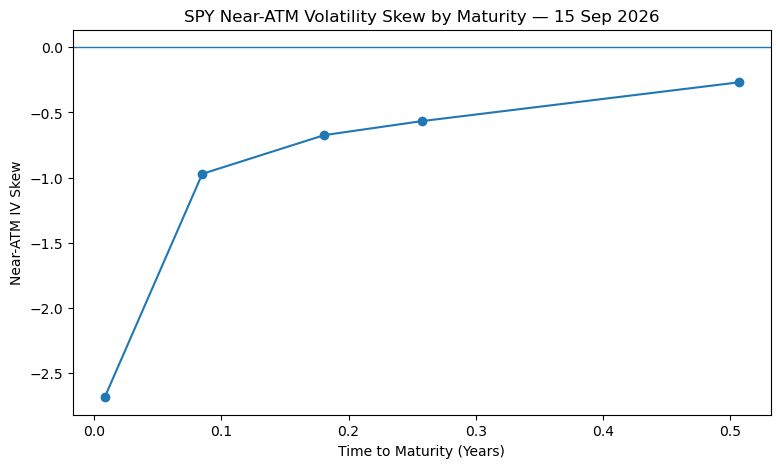

In [22]:
plt.figure(figsize=(9, 5))

plt.plot(
    skew_results_df["T"],
    skew_results_df["skew"],
    marker="o"
)

plt.axhline(0, linewidth=1)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Near-ATM IV Skew")
plt.title("SPY Near-ATM Volatility Skew by Maturity — 15 Sep 2026")

plt.show()

In [23]:
atm_term = vol_surface[(vol_surface["moneyness"] >= 0.99) & (vol_surface["moneyness"] <= 1.01)].copy()

In [24]:
atm_term.groupby("expiration").size()

expiration
2026-09-18 00:00:00+00:00    15
2026-10-16 00:00:00+00:00    15
2026-11-20 00:00:00+00:00     3
2026-12-18 00:00:00+00:00     3
2027-03-19 00:00:00+00:00     3
dtype: int64

In [25]:
atm_term_structure = (
    atm_term
    .groupby("expiration")["implied_vol"]
    .median()
)

print(atm_term_structure)

expiration
2026-09-18 00:00:00+00:00    0.162843
2026-10-16 00:00:00+00:00    0.135992
2026-11-20 00:00:00+00:00    0.150991
2026-12-18 00:00:00+00:00    0.153435
2027-03-19 00:00:00+00:00    0.161796
Name: implied_vol, dtype: float64


In [26]:
atm_T = (
    atm_term
    .groupby("expiration")["T"]
    .median()
)

In [27]:
term_structure_df = pd.DataFrame({
    "T": atm_T,
    "atm_iv": atm_term_structure
})

term_structure_df

,T,atm_iv
expiration,,
2026-09-18 00:00:00+00:00,0.008219,0.162843
2026-10-16 00:00:00+00:00,0.084932,0.135992
2026-11-20 00:00:00+00:00,0.180822,0.150991
2026-12-18 00:00:00+00:00,0.257534,0.153435
2027-03-19 00:00:00+00:00,0.506849,0.161796


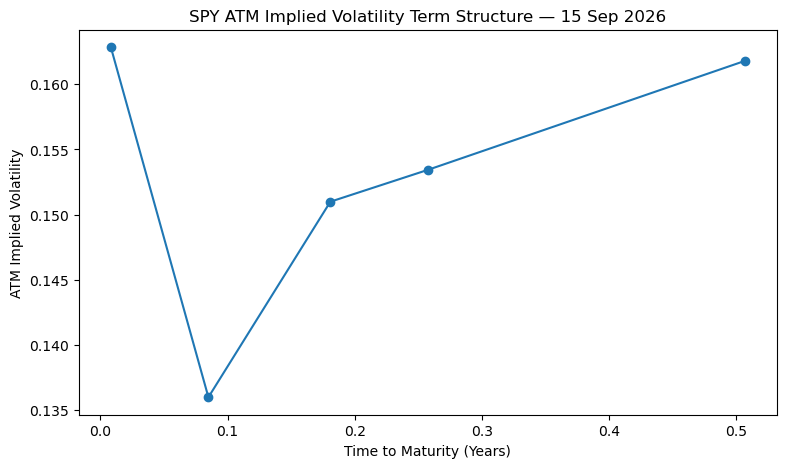

In [28]:
plt.figure(figsize=(9, 5))

plt.plot(
    term_structure_df["T"],
    term_structure_df["atm_iv"],
    marker="o"
)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("ATM Implied Volatility")
plt.title("SPY ATM Implied Volatility Term Structure — 15 Sep 2026")

plt.show()

In [29]:
for expiry, group in vol_surface.groupby("expiration"):
    print(
        expiry.date(),
        "min:", round(group["moneyness"].min(), 3),
        "max:", round(group["moneyness"].max(), 3)
    )

2026-09-18 min: 0.938 max: 1.02
2026-10-16 min: 0.819 max: 1.07
2026-11-20 min: 0.826 max: 1.096
2026-12-18 min: 0.819 max: 1.156
2027-03-19 min: 0.832 max: 1.123


In [30]:
oct_surface = vol_surface[
    vol_surface["expiration"] == pd.Timestamp("2026-10-16", tz="UTC")
].copy()

In [31]:
oct_surface["distance_095"] = abs(oct_surface["moneyness"] - 0.95)
oct_surface["distance_105"] = abs(oct_surface["moneyness"] - 1.05)

In [32]:
downside = oct_surface.loc[oct_surface["distance_095"].idxmin()]
upside = oct_surface.loc[oct_surface["distance_105"].idxmin()]

print(
    "Downside:",
    downside["moneyness"],
    downside["implied_vol"]
)

print(
    "Upside:",
    upside["moneyness"],
    upside["implied_vol"]
)

Downside: 0.9498270456851566 0.1952906792291199
Upside: 1.0502260101803889 0.1079122888961903


In [33]:
downside_premium = downside["implied_vol"] - upside["implied_vol"]

print("Downside IV premium:", downside_premium)
print("Downside IV premium (vol points):", downside_premium * 100)

Downside IV premium: 0.08737839033292961
Downside IV premium (vol points): 8.737839033292962


In [34]:
premium_results = []

usable_expiries = vol_surface[
    vol_surface["expiration"] != pd.Timestamp("2026-09-18", tz="UTC")
]

for expiry, group in usable_expiries.groupby("expiration"):

    down_idx = abs(group["moneyness"] - 0.95).idxmin()
    up_idx = abs(group["moneyness"] - 1.05).idxmin()

    downside = group.loc[down_idx]
    upside = group.loc[up_idx]

    premium_results.append({
        "expiration": expiry,
        "T": group["T"].iloc[0],
        "down_moneyness": downside["moneyness"],
        "down_iv": downside["implied_vol"],
        "up_moneyness": upside["moneyness"],
        "up_iv": upside["implied_vol"],
        "downside_premium": downside["implied_vol"] - upside["implied_vol"]
    })

premium_df = pd.DataFrame(premium_results)

premium_df

,expiration,T,down_moneyness,down_iv,up_moneyness,up_iv,downside_premium
0,2026-10-16 00:00:00+00:00,0.084932,0.949827,0.195291,1.050226,0.107912,0.087378
1,2026-11-20 00:00:00+00:00,0.180822,0.951148,0.185289,1.050226,0.122430,0.062859
2,2026-12-18 00:00:00+00:00,0.257534,0.951148,0.183556,1.050226,0.128446,0.055110
3,2027-03-19 00:00:00+00:00,0.506849,0.944543,0.183576,1.050226,0.145524,0.038052


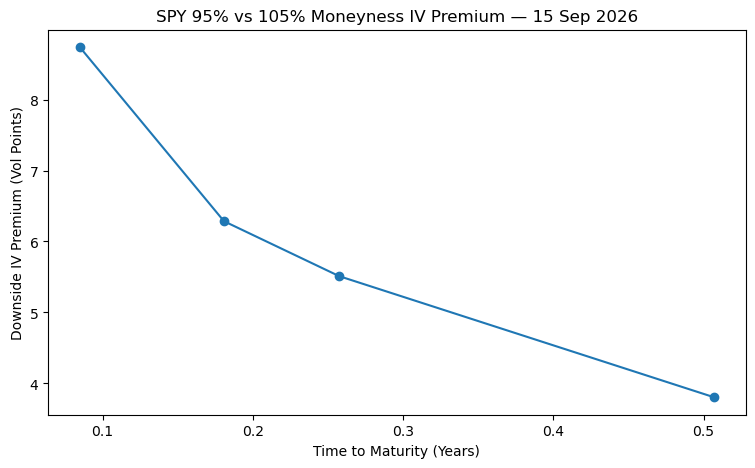

In [35]:
plt.figure(figsize=(9, 5))

plt.plot(
    premium_df["T"],
    premium_df["downside_premium"] * 100,
    marker="o"
)

plt.xlabel("Time to Maturity (Years)")
plt.ylabel("Downside IV Premium (Vol Points)")
plt.title("SPY 95% vs 105% Moneyness IV Premium — 15 Sep 2026")

plt.show()

## Key Findings

- SPY exhibits a pronounced negative implied-volatility skew across all observed maturities, with lower-strike options carrying higher implied volatility than higher-strike options.
- Near-ATM skew becomes progressively flatter with maturity. The estimated slope declines in magnitude from approximately -2.68 for the shortest-dated expiry to -0.27 at approximately six months.
- The downside volatility premium shows the same pattern. For the October expiry, implied volatility near 95% moneyness exceeds implied volatility near 105% moneyness by approximately 8.74 volatility points; by the March expiry, this difference falls to approximately 3.81 volatility points.
- The ATM volatility term structure is non-monotonic in this snapshot: ATM IV falls from approximately 16.3% for the shortest maturity to 13.6% at one month before rising toward 16.2% at six months.

## Limitations

SPY options are American-style and SPY pays discrete dividends, while implied volatilities here are estimated using a dividend-adjusted European Black-Scholes model with a constant dividend yield. The call-put IV discontinuity observed around ATM is therefore likely to reflect, at least partly, model and input approximation error.

Very short-dated estimates should also be interpreted cautiously because implied volatility becomes more sensitive to timing and pricing assumptions close to expiration. Results represent a single cross-sectional market snapshot rather than the evolution of the volatility surface through time. t
